In [ ]:
import cv2
def canny_processing(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    blur = cv2.GaussianBlur(
        gray, 
        (5,5), # Guassian kernel 
        0
    )
    edges = cv2.Canny(blur, 50, 150)
    return edges


In [141]:
sample1 = cv2.imread('1.webp')
edges = canny_processing(img=sample1)

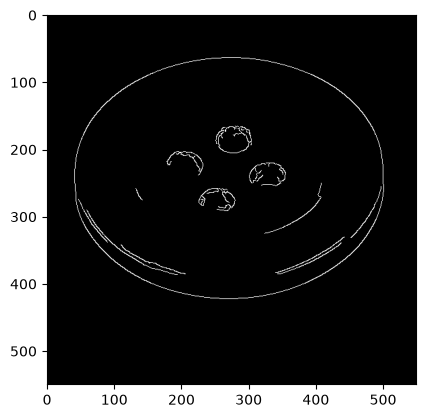

In [142]:
import matplotlib.pyplot as plt
plt.imshow(edges, cmap="gray")

In [143]:
??cv2.GaussianBlur

Docstring:
GaussianBlur(src, ksize, sigmaX[, dst[, sigmaY[, borderType[, hint]]]]) -> dst
.   @brief Blurs an image using a Gaussian filter.
.   
.   The function convolves the source image with the specified Gaussian kernel. In-place filtering is
.   supported.
.   
.   @param src input image; the image can have any number of channels, which are processed
.   independently, but the depth should be CV_8U, CV_16U, CV_16S, CV_32F or CV_64F.
.   @param dst output image of the same size and type as src.
.   @param ksize Gaussian kernel size. ksize.width and ksize.height can differ but they both must be
.   positive and odd. Or, they can be zero's and then they are computed from sigma.
.   @param sigmaX Gaussian kernel standard deviation in X direction.
.   @param sigmaY Gaussian kernel standard deviation in Y direction; if sigmaY is zero, it is set to be
.   equal to sigmaX, if both sigmas are zeros, they are computed from ksize.width and ksize.height,
.   respectively (see #getGaussianKer

In [144]:
edges

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(550, 550), dtype=uint8)

# Normal Form

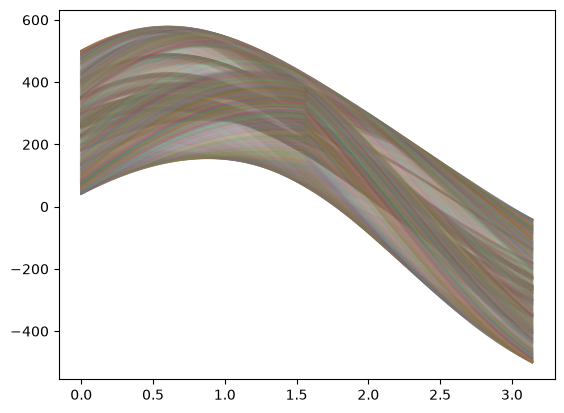

In [159]:
import numpy as np
import matplotlib.pyplot as plt
Y_axis, X_axis = np.nonzero(edges)
theta = np.linspace(0, np.pi, 100)
for i in range(len(X_axis)):
    p = X_axis[i]*np.cos(theta) + Y_axis[i]*np.sin(theta)
    plt.plot(theta, p, alpha = 0.05)

plt.show()

In [146]:
sample1.shape

(550, 550, 3)

In [174]:
THETA_STEP = 2
DISTANCE_STEP = 2
chosen_thetas = np.arange(0, 180 +  1, THETA_STEP, dtype=np.int64)
chosen_distance = np.arange(0, np.sqrt((sample1.shape[0])**2 + (sample1.shape[1])**2), DISTANCE_STEP, dtype=np.int64)
(chosen_thetas, chosen_distance)

(array([  0,   2,   4,   6,   8,  10,  12,  14,  16,  18,  20,  22,  24,
         26,  28,  30,  32,  34,  36,  38,  40,  42,  44,  46,  48,  50,
         52,  54,  56,  58,  60,  62,  64,  66,  68,  70,  72,  74,  76,
         78,  80,  82,  84,  86,  88,  90,  92,  94,  96,  98, 100, 102,
        104, 106, 108, 110, 112, 114, 116, 118, 120, 122, 124, 126, 128,
        130, 132, 134, 136, 138, 140, 142, 144, 146, 148, 150, 152, 154,
        156, 158, 160, 162, 164, 166, 168, 170, 172, 174, 176, 178, 180]),
 array([  0,   2,   4,   6,   8,  10,  12,  14,  16,  18,  20,  22,  24,
         26,  28,  30,  32,  34,  36,  38,  40,  42,  44,  46,  48,  50,
         52,  54,  56,  58,  60,  62,  64,  66,  68,  70,  72,  74,  76,
         78,  80,  82,  84,  86,  88,  90,  92,  94,  96,  98, 100, 102,
        104, 106, 108, 110, 112, 114, 116, 118, 120, 122, 124, 126, 128,
        130, 132, 134, 136, 138, 140, 142, 144, 146, 148, 150, 152, 154,
        156, 158, 160, 162, 164, 166, 168, 170, 1

In [175]:
RATIO = np.pi / 180
ACUMULATOR = np.zeros((np.max(chosen_distance), len(chosen_thetas)))
print(ACUMULATOR.shape)
for i in range(len(Y_axis)):
    _distance_range = X_axis[i]*np.cos((RATIO*chosen_thetas)) + Y_axis[i]*np.sin(RATIO*chosen_thetas)
    int_distance_range = _distance_range.astype(np.int64)
    # print(int_distance_range)
    
    
    for j in range(len(int_distance_range)):
        if int_distance_range[j] in chosen_distance:
            print(chosen_thetas[j])
            # print(int_distance_range[j], chosen_thetas[j])
            ACUMULATOR[int_distance_range[j]][j] += 1

(776, 91)
0
2
8
10
18
22
30
34
44
48
60
64
70
72
74
76
82
86
88
94
98
100
4
6
12
14
16
20
24
26
28
32
36
38
40
42
46
50
52
54
56
62
68
70
72
74
76
82
88
94
98
100
0
2
8
10
18
22
24
28
30
34
36
42
44
48
50
52
54
56
58
62
66
68
70
72
74
76
78
82
84
88
94
100
4
6
12
14
16
20
26
32
38
44
46
48
58
60
66
68
76
78
82
84
88
94
100
102
0
2
8
10
18
22
24
26
28
30
34
36
38
40
42
46
52
54
60
64
66
76
78
84
88
94
100
102
4
6
12
14
16
20
30
32
34
44
48
50
52
54
56
62
64
78
80
84
88
94
96
100
102
0
2
8
10
18
22
24
26
28
32
36
38
40
46
48
56
58
62
68
70
72
78
80
84
88
94
96
102
4
6
12
14
16
20
30
34
42
46
52
58
60
62
66
68
70
72
74
80
84
88
94
96
102
0
2
8
10
16
18
22
24
26
28
32
44
48
50
52
54
56
60
64
66
68
70
72
74
80
84
88
94
96
4
6
12
14
20
30
34
36
38
40
42
46
48
56
64
66
74
76
80
84
88
94
96
98
0
2
8
10
16
18
24
26
32
42
46
58
62
64
74
76
80
84
88
94
96
98
4
6
12
14
20
22
28
30
36
38
40
44
48
50
52
54
60
62
76
82
84
88
96
98
100
0
2
8
10
16
18
24
26
32
34
40
42
46
48
54
56
60
66
68
70
76
78
82


In [176]:
ACUMULATOR

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(776, 91))

In [177]:
max_x, max_y = 0, 0
max_value = ACUMULATOR[0][0]
for i in range(ACUMULATOR.shape[0]):
    for j in range(ACUMULATOR.shape[1]):
        if ACUMULATOR[i][j] > max_value:
            max_value = ACUMULATOR[i][j]
            max_x, max_y = i, j

print(max_x, max_y)


292 55


In [170]:
p_range, theta_range = np.nonzero(ACUMULATOR)

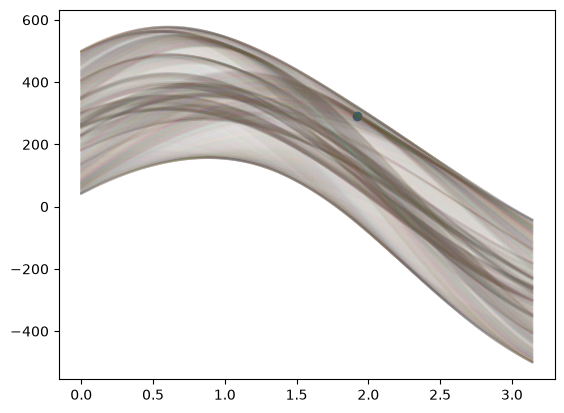

In [172]:
for i in range(len(X_axis)):
    p = X_axis[i]*np.cos(theta) + Y_axis[i]*np.sin(theta)
    plt.plot(theta, p, alpha = 0.01)
plt.scatter(RATIO*chosen_thetas[max_y], max_x, alpha=1)
plt.show()

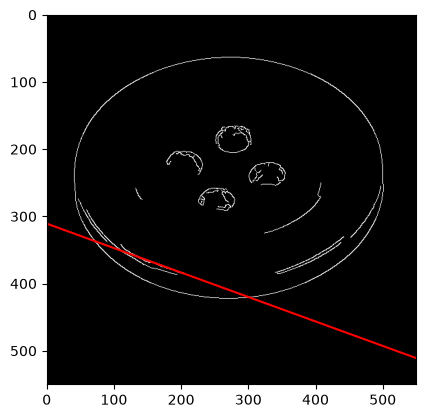

In [173]:
theta = RATIO * chosen_thetas[max_y]
rho = max_x                            
h, w = edges.shape

plt.imshow(edges, cmap='gray')
if np.isclose(np.sin(theta), 0):
    plt.axvline(rho / np.cos(theta), color='red')
else:
    x = np.array([0, w])
    y = (rho - x * np.cos(theta)) / np.sin(theta)
    plt.plot(x, y, color='red')

plt.xlim(0, w); plt.ylim(h, 0)
plt.show()